Total papers: 216

Categories:
category
Condensed Matter    82
Astrophysics        78
Other Physics       48
Quantum Physics      8
Name: count, dtype: int64

Cleaned dataset: 166
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters:
{'classifier__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}

Best cross-validation F1:
0.461

Test Accuracy:
0.8529

Classification Report:
                  precision    recall  f1-score   support

    Astrophysics       0.93      0.81      0.87        16
Condensed Matter       0.80      1.00      0.89        16
   Other Physics       0.00      0.00      0.00         1
 Quantum Physics       0.00      0.00      0.00         1

        accuracy                           0.85        34
       macro avg       0.43      0.45      0.44        34
    weighted avg       0.81      0.85      0.83        34



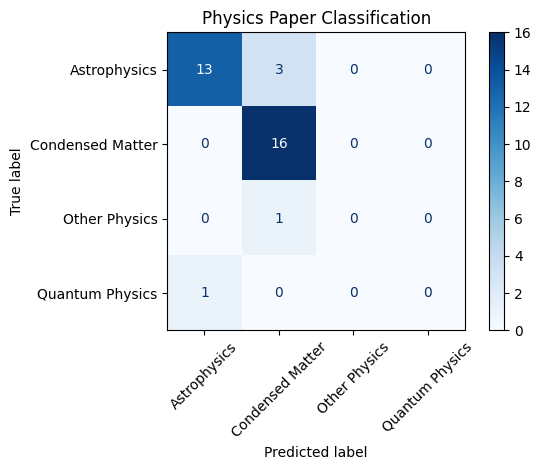


Abstract: We investigate black holes and galaxy formation.
Prediction: Astrophysics

Abstract: We study superconductivity and magnetic materials.
Prediction: Condensed Matter

Abstract: We investigate quantum entanglement and quantum computing.
Prediction: Condensed Matter

Model saved successfully!


In [6]:
# ======================================
# PHYSICS PAPER CLASSIFIER - UPDATED
# ======================================

import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# ======================================
# 1. LOAD UPDATED DATASET
# ======================================

df = pd.read_csv("physics_papers_updated.csv")

print("Total papers:", len(df))
print("\nCategories:")
print(df["category"].value_counts())


# ======================================
# 2. CLEAN DATA
# ======================================

df = df.dropna(subset=["abstract", "category"]).copy()

df["abstract"] = df["abstract"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()

df = df[
    (df["abstract"] != "") &
    (df["category"] != "")
]

df = df.drop_duplicates(subset=["abstract"])

print("\nCleaned dataset:", len(df))


# ======================================
# 3. FEATURES AND TARGET
# ======================================

X = df["abstract"]
y = df["category"]


# ======================================
# 4. TRAIN / TEST SPLIT
# ======================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ======================================
# 5. CREATE ML PIPELINE
# ======================================

pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            stop_words="english",
            max_features=10000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])


# ======================================
# 6. CROSS-VALIDATION
# ======================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


# ======================================
# 7. HYPERPARAMETER TUNING
# ======================================

params = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "classifier__C": [0.1, 1, 10]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("\nBest parameters:")
print(grid.best_params_)

print("\nBest cross-validation F1:")
print(round(grid.best_score_, 4))


# ======================================
# 8. BEST MODEL
# ======================================

best_model = grid.best_estimator_


# ======================================
# 9. MODEL EVALUATION
# ======================================

y_pred = best_model.predict(X_test)

print("\nTest Accuracy:")
print(round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


# ======================================
# 10. CONFUSION MATRIX
# ======================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Physics Paper Classification")
plt.tight_layout()
plt.show()


# ======================================
# 11. TEST NEW ABSTRACTS
# ======================================

examples = [
    "We investigate black holes and galaxy formation.",

    "We study superconductivity and magnetic materials.",

    "We investigate quantum entanglement and quantum computing."
]

predictions = best_model.predict(examples)

for abstract, prediction in zip(examples, predictions):
    print("\nAbstract:", abstract)
    print("Prediction:", prediction)


# ======================================
# 12. SAVE MODEL
# ======================================

joblib.dump(
    best_model,
    "physics_classifier.joblib"
)

print("\nModel saved successfully!")
